In [16]:
import pandas as pd
import numpy as np

In [17]:
df = pd.read_csv("Cleaned_Dataset.csv")
df.head()

,Unnamed: 0,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,...,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating text,Votes
0,0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,...,1100,Botswana Pula(P),1,0,0,0,3,4.8,4,314
1,1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,...,1200,Botswana Pula(P),1,0,0,0,3,4.5,4,591
2,2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,...,4000,Botswana Pula(P),1,0,0,0,4,4.4,3,270
3,3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,...,1500,Botswana Pula(P),0,0,0,0,4,4.9,4,365
4,4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,...,1500,Botswana Pula(P),1,0,0,0,4,4.8,4,229


In [18]:
for col in ['Restaurant Name', 'City']:
    df[col] = df[col].str.strip()

In [20]:
df = df[['Restaurant Name', 'Longitude', 'Latitude', 'Aggregate rating', 'City']]
df.head()

,Restaurant Name,Longitude,Latitude,Aggregate rating,City
0,Le Petit Souffle,121.027535,14.565443,4.8,Makati City
1,Izakaya Kikufuji,121.014101,14.553708,4.5,Makati City
2,Heat - Edsa Shangri-La,121.056831,14.581404,4.4,Mandaluyong City
3,Ooma,121.056475,14.585318,4.9,Mandaluyong City
4,Sambo Kojin,121.057508,14.584450,4.8,Mandaluyong City


In [ ]:
df.duplicated().sum()

np.int64(8)

In [ ]:
df.drop_duplicates()

,Restaurant Name,Longitude,Latitude,Aggregate rating
0,Le Petit Souffle,121.027535,14.565443,4.8
1,Izakaya Kikufuji,121.014101,14.553708,4.5
2,Heat - Edsa Shangri-La,121.056831,14.581404,4.4
3,Ooma,121.056475,14.585318,4.9
4,Sambo Kojin,121.057508,14.584450,4.8
...,...,...,...,...
9537,Naml۱ Gurme,28.977392,41.022793,4.1
9538,Ceviz A��ac۱,29.041297,41.009847,4.2
9539,Huqqa,29.034640,41.055817,3.7
9540,A���k Kahve,29.036019,41.057979,4.0


In [ ]:
df.columns

Index(['Restaurant Name', 'Longitude', 'Latitude', 'Aggregate rating'], dtype='str')

In [ ]:
import folium
from folium.plugins import MarkerCluster

restaurants_map = folium.Map(location=[df['Latitude'].mean(), df['Longitude'].mean()], zoom_start=5)

marker_cluster = MarkerCluster().add_to(restaurants_map)
for _, row in df.iterrows():
        popup_info = f"""
    Restaurant: {row['Restaurant Name']}<br>
    Rating: {row['Aggregate rating']}
    """
        folium.Marker([row['Latitude'], row['Longitude']], popup= popup_info).add_to(marker_cluster)

restaurants_map

# Conclusion

## Country:
- India has exeptionally highi concentration of restaurants.
- Africa, North America Moderate concentration.
- Europe, Hawaii, New Zealand and Australia the least.

## Cities:
- India(New Delhi has the highest concentration of restaurants).
- North America(Albany, Atlanta), 
- Pennsylvania, Portland, Calgary, Honolulu, 

In [23]:
city_rating = df.groupby('City')['Aggregate rating'].mean().sort_values(ascending=False)
city_rating.head(10)

City
Inner City          4.900000
Quezon City         4.800000
Makati City         4.650000
Pasig City          4.633333
Mandaluyong City    4.625000
Beechworth          4.600000
London              4.535000
Taguig City         4.525000
Lincoln             4.500000
Tagaytay City       4.500000
Name: Aggregate rating, dtype: float64

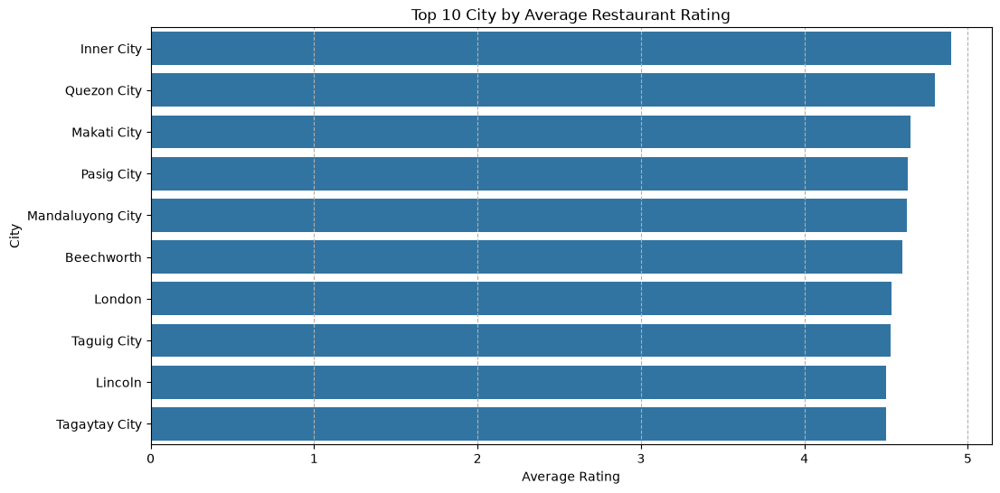

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    x= city_rating.head(10).values,
    y= city_rating.head(10).index
)

plt.xlabel('Average Rating')
plt.ylabel('City')
plt.grid(axis='x', linestyle='--')
plt.title('Top 10 City by Average Restaurant Rating')
plt.show()

## Observation:

- Inner City has the highest average restaurant rating, approximately 4.9.
- Quezon City and Makati City are ranked second and third.
- Tagaytay City has the lowest average rating among these top 10, but it is still around 4.5.
- The difference between the highest and lowest average ratings is relatively small.

eventhough, different cities have different ratings but, concluding location of the restaurant directly affects the rating is not always true.